<a href="https://colab.research.google.com/github/rohit-jain8/Problem-Set-4/blob/main/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [37]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [38]:
store_rng = np.random.default_rng(42)
revenue_rng = np.random.default_rng(43)

floor_area = store_rng.uniform(1, 12, N_STORES)
foot_traffic = store_rng.uniform(2, 18, N_STORES) + 0.85 * floor_area
median_income = store_rng.uniform(40, 125, N_STORES)
years_open = store_rng.integers(1, 31, N_STORES)

activity_index = (
    0.70 * floor_area
    + 0.30 * foot_traffic
    + store_rng.normal(0, 0.08, N_STORES)
)
noise_predictors = store_rng.normal(0, 1, size=(N_STORES, 7))

# Only floor area above 7,000 square feet contributes to the curve.
area_above_7000 = floor_area - 7
area_above_7000[area_above_7000 < 0] = 0

error_sd = 2 + 2.7 * floor_area
revenue_error = revenue_rng.normal(0, error_sd)

# Monthly revenue is measured in thousands of dollars.
revenue = (
    45
    + 16 * floor_area
    - 1.5 * area_above_7000**2
    + 9 * foot_traffic
    + 0.55 * median_income
    + 1.3 * years_open
    + revenue_error
)

stores = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "activity_index": activity_index,
})

for column in range(7):
    stores[f"noise_{column + 1}"] = noise_predictors[:, column]

X = stores.copy()
y = pd.Series(revenue, index=stores.index, name="monthly_revenue")
stores["monthly_revenue"] = y

print(f"{len(stores)} stores and {X.shape[1]} predictors")
display(stores.head())

400 stores and 12 predictors


,floor_area,foot_traffic,median_income,years_open,activity_index,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,monthly_revenue
0,9.514,14.917,102.779,1,11.104,-1.176,-0.778,-0.630,-1.057,-1.052,-0.144,-1.217,386.586
1,5.828,21.649,66.958,17,10.647,0.842,-0.918,2.810,-0.451,0.072,-1.295,1.706,404.034
2,10.445,23.379,115.652,23,14.186,1.120,0.297,-1.347,0.211,-1.121,1.462,0.809,480.548
3,8.671,11.140,90.476,17,9.481,0.095,-2.436,-0.983,0.688,1.213,1.109,-1.592,328.577
4,2.036,19.683,50.712,12,7.300,0.302,1.016,-1.658,-0.008,0.274,-0.301,-1.852,283.282


I simulated 400 stores with 12 predictors. Floor area ranges from 1,000 to 12,000 square feet, and larger stores tend to get more foot traffic. Local median income ranges from 40,000 to 125,000 dollars, and stores have been open for 1 to 30 years. I also included seven independent standard normal noise variables and an activity index made from 0.70 times floor area plus 0.30 times foot traffic, with a small random error (SD 0.08).

The true equation for monthly revenue, in thousands of dollars, is:

Revenue = 45 + 16A - 1.5 * max(A - 7, 0)^2 + 9F + 0.55I + 1.3T + error

A is floor area in thousands of square feet, F is monthly foot traffic in thousands of visits, I is local median income in thousands of dollars, and T is years open. The activity index and noise variables do not enter the revenue equation.

Holding the other predictors fixed, revenue still rises with floor area, but it rises more slowly once a store is bigger than 7,000 square feet. The error has a mean of zero and a standard deviation of 2 + 2.7A, so revenue varies more around its expected value for bigger stores.

### Step 1.2: Fit it the way they did (12 pts)

In [39]:
from sklearn.model_selection import train_test_split

X_with_const = sm.add_constant(X)
full_model = sm.OLS(y, X_with_const).fit()

X_train, X_test, y_train, y_test = train_test_split(
    X_with_const, y, test_size=0.20, random_state=42
)

train_model = sm.OLS(y_train, X_train).fit()
test_predictions = train_model.predict(X_test)

test_rss = np.sum((y_test - test_predictions) ** 2)
test_tss = np.sum((y_test - y_test.mean()) ** 2)

full_r2 = full_model.rsquared
test_r2 = 1 - test_rss / test_tss

print(f"In-sample R-squared: {full_r2:.4f}")
print(f"Held-out R-squared: {test_r2:.4f}")
print(f"Gap (held-out minus in-sample): {test_r2 - full_r2:.4f}")

In-sample R-squared: 0.9410
Held-out R-squared: 0.9514
Gap (held-out minus in-sample): 0.0104


I fit OLS using all 12 predictors and all 400 stores. The in-sample R-squared was 0.9410, which matches the 0.94 in the handover note when rounded. I then fit the same model on 320 stores and tested it on the other 80. The held-out R-squared was 0.9514, about 0.0104 higher than the in-sample score.

The held-out score was slightly higher on this split. A different group of test stores could give a different result. Both scores summarize fit across stores, so we still need to check whether the model consistently overpredicts revenue for the biggest stores.

### Step 1.3: Say what R-squared is (8 pts)

In [40]:
noise_rng = np.random.default_rng(44)
X_extra_noise = X.copy()

for column in range(1, 4):
    X_extra_noise[f"extra_noise_{column}"] = noise_rng.normal(0, 1, len(X))

noise_model = sm.OLS(y, sm.add_constant(X_extra_noise)).fit()

n = len(y)
original_p = X.shape[1]
noise_p = X_extra_noise.shape[1]
noise_r2 = noise_model.rsquared

original_adj_r2 = 1 - (1 - full_r2) * (n - 1) / (n - original_p - 1)
noise_adj_r2 = 1 - (1 - noise_r2) * (n - 1) / (n - noise_p - 1)

print(f"Original R-squared: {full_r2:.5f}")
print(f"R-squared with extra noise: {noise_r2:.5f}")
print(f"Original adjusted R-squared: {original_adj_r2:.5f}")
print(f"Adjusted R-squared with extra noise: {noise_adj_r2:.5f}")

Original R-squared: 0.94101
R-squared with extra noise: 0.94168
Original adjusted R-squared: 0.93918
Adjusted R-squared with extra noise: 0.93940


When we add a predictor, OLS can always give it a coefficient of zero and get the same fit as before. With the same stores and outcome, adding a predictor can only reduce the residual sum of squares or leave it unchanged. That means in-sample R-squared can only increase or stay the same.

After I added three random noise variables, R-squared went from 0.94101 to 0.94168, and adjusted R-squared went from 0.93918 to 0.93940. The noise variables improved the fit by chance, and this time the improvement was enough to outweigh the penalty for adding predictors. This is why I would use held-out performance to compare models for prediction.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

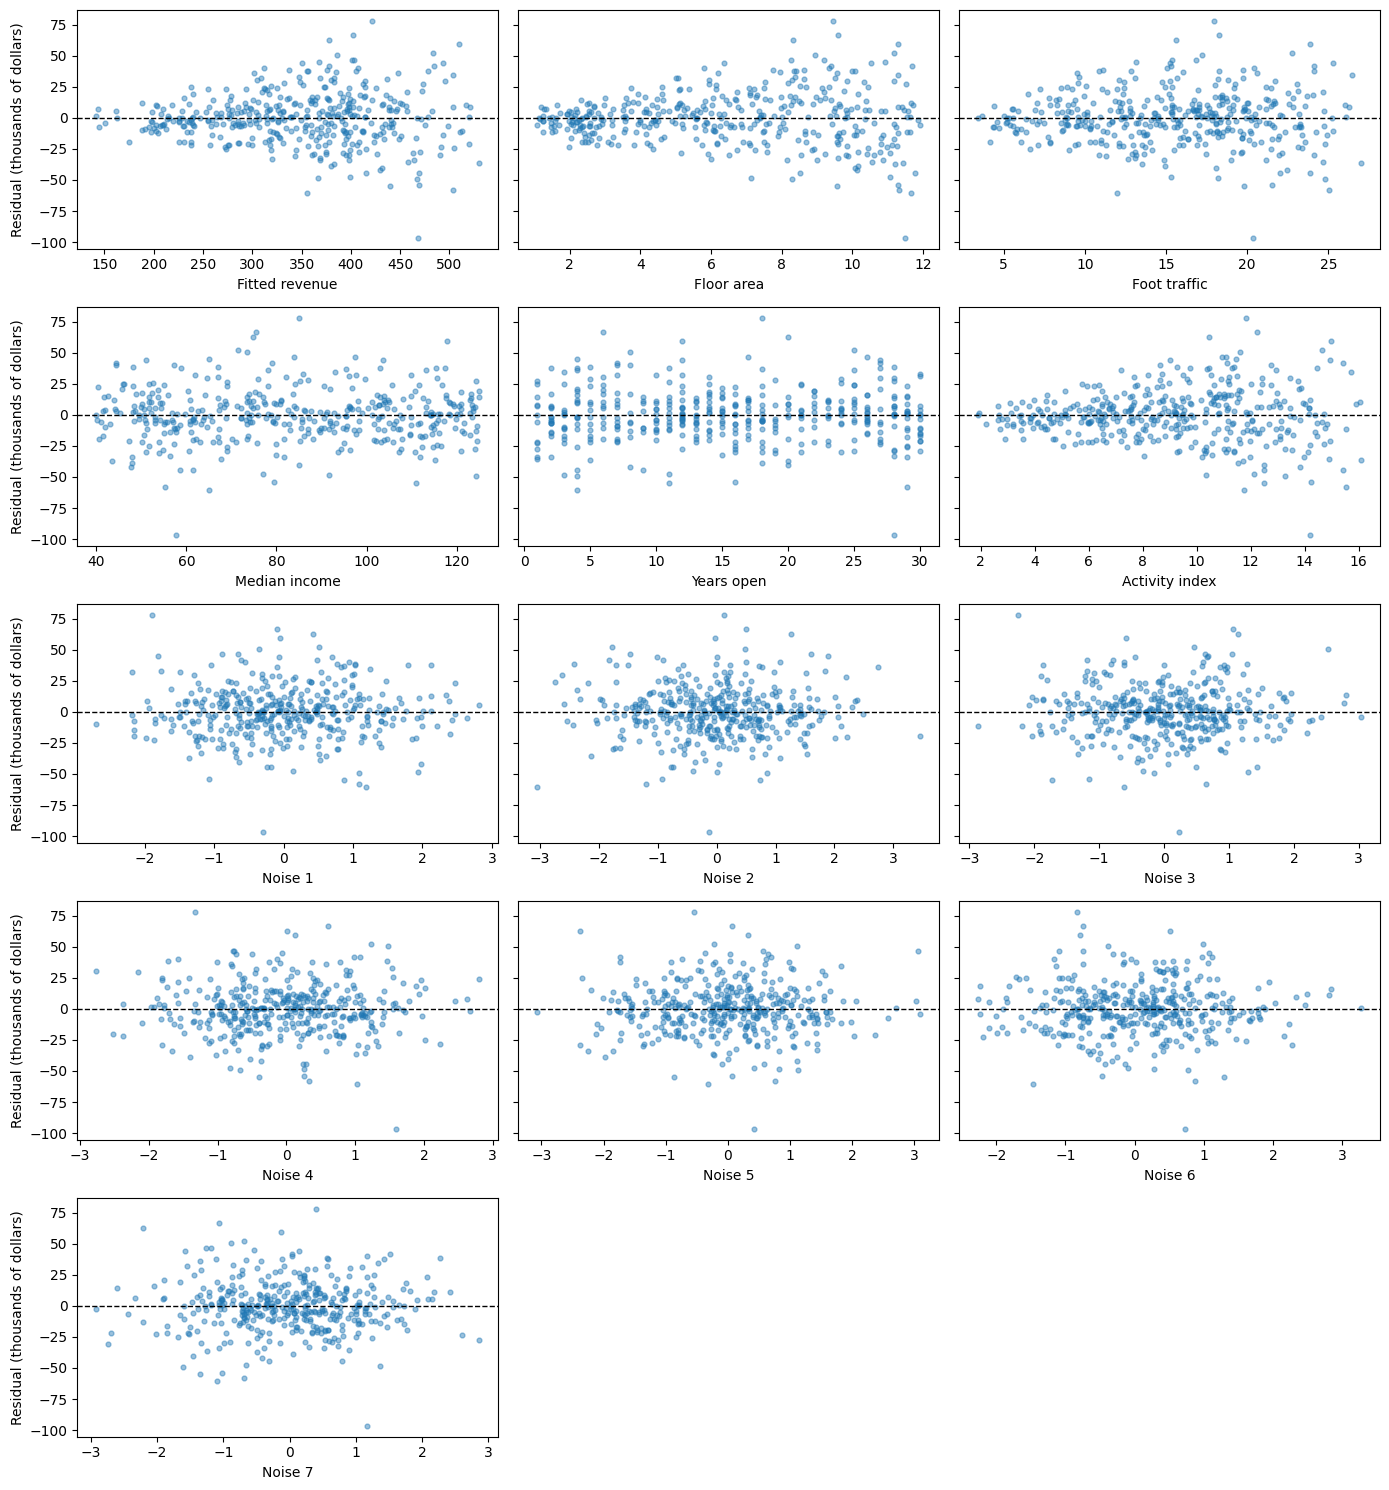

,mean_residual,residual_sd
Smallest 25%,-3.11,9.04
Second 25%,2.64,15.68
Third 25%,3.98,22.88
Largest 25%,-3.51,29.52


In [41]:
residuals = full_model.resid

plot_data = pd.DataFrame({"fitted_revenue": full_model.fittedvalues})

for column in X.columns:
    plot_data[column] = X[column]

fig, axes = plt.subplots(5, 3, figsize=(14, 15), sharey=True)

for ax, column in zip(axes.flat, plot_data.columns):
    ax.scatter(plot_data[column], residuals, s=12, alpha=0.45)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(column.replace("_", " ").capitalize())

for ax in axes[:, 0]:
    ax.set_ylabel("Residual (thousands of dollars)")

for ax in axes.flat[len(plot_data.columns):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()

# Sort by floor area and split the 400 stores into four groups of 100.
sorted_stores = X["floor_area"].sort_values().index
group_size = len(sorted_stores) // 4
group_labels = ["Smallest 25%", "Second 25%", "Third 25%", "Largest 25%"]
group_means = []
group_sds = []

for i in range(4):
    start = i * group_size
    end = start + group_size
    store_ids = sorted_stores[start:end]
    group_residuals = residuals.loc[store_ids]

    group_means.append(group_residuals.mean())
    group_sds.append(group_residuals.std())

residual_summary = pd.DataFrame({
    "mean_residual": group_means,
    "residual_sd": group_sds,
}, index=group_labels)

display(residual_summary.round(2))

The residuals spread out as floor area increases. The residual standard deviation rose from 9.04 thousand dollars for the smallest quarter of stores to 29.52 thousand dollars for the largest quarter. This is heteroskedasticity, so the constant variance assumption is violated. By itself, changing variance does not bias the OLS coefficients if the mean equation is correct, but it can make the usual OLS standard errors unreliable. Robust standard errors can account for the changing variance.

The average residual was negative for the smallest and largest quarters and positive for the two middle quarters. That pattern suggests the model missed curvature in the relationship between floor area and revenue. The model uses a straight-line floor area term, but in the simulation the effect of extra floor area gets smaller above 7,000 square feet. This violates the conditional mean assumption because the model gets average revenue wrong in a way that depends on store size. Robust standard errors can improve inference for the fitted coefficients, but fixing the prediction pattern requires changing the mean equation.

### Step 2.2: The over-forecast on big stores (15 pts)

In [42]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# A positive forecast error means predicted revenue exceeded actual revenue.
forecast_error = full_model.fittedvalues - y
mean_error_by_size = -residual_summary["mean_residual"]

print("Mean forecast error by store size (thousands of dollars)")
display(mean_error_by_size.round(2))

top_count = len(sorted_stores) // 10
largest_store_ids = sorted_stores[-top_count:]
largest_store_errors = forecast_error.loc[largest_store_ids]

print(f"Number of stores in the largest 10%: {len(largest_store_errors)}")
print(f"Mean forecast error: {largest_store_errors.mean():.2f} thousand dollars")
print(f"Share over-forecasted: {(largest_store_errors > 0).mean():.1%}")

vif_values = []

for column in range(1, X_with_const.shape[1]):
    vif = variance_inflation_factor(X_with_const.to_numpy(), column)
    vif_values.append(vif)

vif_table = pd.DataFrame({
    "predictor": X.columns,
    "VIF": vif_values,
})

display(vif_table.sort_values("VIF", ascending=False).round(2))

Mean forecast error by store size (thousands of dollars)


,mean_residual
Smallest 25%,3.11
Second 25%,-2.64
Third 25%,-3.98
Largest 25%,3.51


Number of stores in the largest 10%: 40
Mean forecast error: 7.84 thousand dollars
Share over-forecasted: 57.5%


,predictor,VIF
4,activity_index,1692.53
0,floor_area,734.50
1,foot_traffic,413.85
6,noise_2,1.07
10,noise_6,1.05
11,noise_7,1.04
3,years_open,1.04
5,noise_1,1.03
7,noise_3,1.03
8,noise_4,1.03


The model over-forecasted monthly revenue by 3.51 thousand dollars on average for the largest quarter of stores. For the 40 largest stores, the average over-forecast rose to 7.84 thousand dollars, and 57.5% of those stores were over-forecasted. The model under-forecasted the two middle size groups on average. This fits the pattern from Step 2.1, where the straight-line model missed the slowdown in revenue growth for the largest stores.

The activity index had the highest VIF at 1,692.53. Floor area and foot traffic also had high VIFs of 734.50 and 413.85 because the index was built from those two variables. This overlap makes it hard to estimate their separate effects and inflates the standard errors of their coefficients. Collinearity by itself does not bias the OLS coefficients, and predictions can still be accurate for stores with similar combinations of area and traffic. Dropping the activity index could make the coefficients easier to interpret. Fixing the over-forecast for the largest stores would require modeling the slowdown in revenue growth.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

,Model,Terms,Training RMSE,Held-out RMSE
0,Floor area only,1,50.12,58.92
1,Four core predictors,4,20.82,22.66
2,Core predictors + curve,5,20.34,22.47
3,All predictors + curve,13,20.18,22.27
4,Full model + squares and interactions,91,17.88,25.46


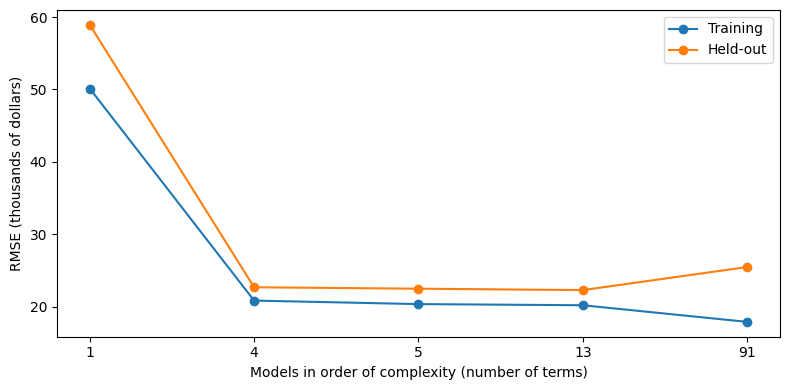

In [43]:
from sklearn.linear_model import LinearRegression

core_predictors = ["floor_area", "foot_traffic", "median_income", "years_open"]
area_curve = area_above_7000 ** 2

core_with_curve = X[core_predictors].copy()
core_with_curve["area_curve"] = area_curve

full_with_curve = X.copy()
full_with_curve["area_curve"] = area_curve

# Multiply each predictor by itself and by the predictors after it.
# This adds each square and each interaction once.
predictor_names = list(X.columns)
full_quadratic = full_with_curve.copy()

for i, first in enumerate(predictor_names):
    for second in predictor_names[i:]:
        column_name = f"{first}_times_{second}"
        full_quadratic[column_name] = X[first] * X[second]

model_inputs = {
    "Floor area only": X[["floor_area"]],
    "Four core predictors": X[core_predictors],
    "Core predictors + curve": core_with_curve,
    "All predictors + curve": full_with_curve,
    "Full model + squares and interactions": full_quadratic,
}

results = []

for name, features in model_inputs.items():
    train_features = features.loc[y_train.index]
    test_features = features.loc[y_test.index]

    model = LinearRegression().fit(train_features, y_train)
    train_predictions = model.predict(train_features)
    test_predictions = model.predict(test_features)

    train_rmse = np.sqrt(np.mean((y_train - train_predictions) ** 2))
    test_rmse = np.sqrt(np.mean((y_test - test_predictions) ** 2))

    results.append([name, features.shape[1], train_rmse, test_rmse])

sweep_results = pd.DataFrame(
    results, columns=["Model", "Terms", "Training RMSE", "Held-out RMSE"]
)
display(sweep_results.round(2))

positions = range(len(sweep_results))

plt.figure(figsize=(8, 4))
plt.plot(positions, sweep_results["Training RMSE"], marker="o", label="Training")
plt.plot(positions, sweep_results["Held-out RMSE"], marker="o", label="Held-out")
plt.xticks(positions, sweep_results["Terms"])
plt.xlabel("Models in order of complexity (number of terms)")
plt.ylabel("RMSE (thousands of dollars)")
plt.legend()
plt.tight_layout()
plt.show()

Training RMSE fell from 50.12 to 17.88 thousand dollars as I added more terms. Held-out RMSE fell from 58.92 to 22.27 thousand dollars, then rose to 25.46 for the most complex model. The lowest held-out error on this split came from the 13-term model, which included all 12 original predictors and the floor area curve.

On the left side of the plot, the simplest model has high error on both sets because floor area alone misses important parts of the revenue relationship. Adding the other core predictors and the curve reduces that bias. On the right side, adding squares and interactions lowers training error but raises held-out error. That pattern is consistent with higher variance because the extra terms can fit noise in the training stores. The 13-term model did best on this split, and I'll use cross-validation in Step 3.2 to choose a model.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [44]:
from sklearn.model_selection import KFold

inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=123)

def mean_cv_rmse(features, revenue):
    fold_errors = []

    for train_rows, val_rows in inner_cv.split(features):
        model = LinearRegression().fit(
            features.iloc[train_rows], revenue.iloc[train_rows]
        )
        predictions = model.predict(features.iloc[val_rows])
        rmse = np.sqrt(np.mean((revenue.iloc[val_rows] - predictions) ** 2))
        fold_errors.append(rmse)

    return np.mean(fold_errors)


# Select a model inside each outer training set.
outer_results = []

for fold, (train_rows, test_rows) in enumerate(outer_cv.split(X), start=1):
    inner_errors = {}

    for name, features in model_inputs.items():
        inner_errors[name] = mean_cv_rmse(
            features.iloc[train_rows], y.iloc[train_rows]
        )

    chosen_name = min(inner_errors, key=inner_errors.get)
    chosen_features = model_inputs[chosen_name]

    model = LinearRegression().fit(
        chosen_features.iloc[train_rows], y.iloc[train_rows]
    )
    predictions = model.predict(chosen_features.iloc[test_rows])
    outer_rmse = np.sqrt(np.mean((y.iloc[test_rows] - predictions) ** 2))
    outer_results.append([fold, chosen_name, outer_rmse])

outer_table = pd.DataFrame(
    outer_results, columns=["Fold", "Selected model", "Outer RMSE"]
)
display(outer_table.round(2))

# Estimate error and an approximate interval from the outer folds.
outer_errors = outer_table["Outer RMSE"]
mean_outer_rmse = outer_errors.mean()
se_outer_rmse = outer_errors.std() / np.sqrt(len(outer_errors))
margin = stats.t.ppf(0.975, df=len(outer_errors) - 1) * se_outer_rmse

print(f"Nested CV RMSE: {mean_outer_rmse:.2f} thousand dollars")
print(f"Approximate 95% interval: {mean_outer_rmse - margin:.2f} to "
      f"{mean_outer_rmse + margin:.2f} thousand dollars")

# Choose and fit the final model using all 400 stores.
final_cv_errors = {}

for name, features in model_inputs.items():
    final_cv_errors[name] = mean_cv_rmse(features, y)

display(pd.Series(final_cv_errors, name="Mean CV RMSE").sort_values().round(2))

final_model_name = min(final_cv_errors, key=final_cv_errors.get)
final_features = model_inputs[final_model_name]
final_model = LinearRegression().fit(final_features, y)

print(f"Final model: {final_model_name}")

,Fold,Selected model,Outer RMSE
0,1,Core predictors + curve,22.60
1,2,Core predictors + curve,24.18
2,3,Core predictors + curve,19.56
3,4,Core predictors + curve,22.90
4,5,Core predictors + curve,15.10


Nested CV RMSE: 20.87 thousand dollars
Approximate 95% interval: 16.35 to 25.39 thousand dollars


,Mean CV RMSE
Core predictors + curve,20.94
All predictors + curve,21.07
Four core predictors,21.28
Full model + squares and interactions,25.14
Floor area only,52.10


Final model: Core predictors + curve


I used five-fold cross-validation to compare the five models. The four core predictors plus the floor area curve had the lowest mean CV RMSE at 20.94 thousand dollars, so I chose that model. It has five terms and was also selected in all five outer folds. The 13-term model did best on the single split in Step 3.1, but the five-term model did best when I compared the models across folds.

The lowest CV error can look too good if I use the same CV results to pick the winner and report its expected error. A model can win partly because it got lucky on those folds. To address this, I used nested cross-validation. I chose a model using only the inner folds, then measured its error on the outer fold that was left out of that choice.

The mean outer-fold RMSE was 20.87 thousand dollars, with an approximate 95% interval of 16.35 to 25.39 thousand dollars. This estimates the error of the model selection process when trained on 320 stores per outer fold. The interval is approximate because the training sets overlap across folds.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

Mean RMSE across five folds (thousands of dollars)
Training stores   Training RMSE   Validation RMSE
             40           19.60             22.58
             80           19.45             21.17
            160           20.46             20.86
            240           20.97             20.94
            320           20.70             20.87


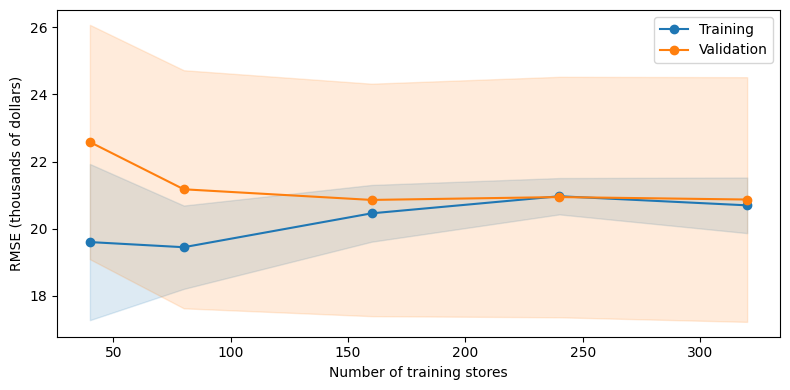

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

training_sizes = [40, 80, 160, 240, 320]
cv = KFold(n_splits=5, shuffle=True, random_state=123)
rng = np.random.default_rng(45)

training_errors = []
validation_errors = []

for train_rows, val_rows in cv.split(final_features):
    train_rows = rng.permutation(train_rows)
    X_val = final_features.iloc[val_rows]
    y_val = y.iloc[val_rows]

    fold_training_errors = []
    fold_validation_errors = []

    for size in training_sizes:
        sample_rows = train_rows[:size]
        X_train = final_features.iloc[sample_rows]
        y_train = y.iloc[sample_rows]

        model = LinearRegression().fit(X_train, y_train)
        train_predictions = model.predict(X_train)
        val_predictions = model.predict(X_val)

        train_rmse = np.sqrt(np.mean((y_train - train_predictions) ** 2))
        val_rmse = np.sqrt(np.mean((y_val - val_predictions) ** 2))

        fold_training_errors.append(train_rmse)
        fold_validation_errors.append(val_rmse)

    training_errors.append(fold_training_errors)
    validation_errors.append(fold_validation_errors)

train_mean = np.mean(training_errors, axis=0)
val_mean = np.mean(validation_errors, axis=0)
train_sd = np.std(training_errors, axis=0, ddof=1)
val_sd = np.std(validation_errors, axis=0, ddof=1)

print("Mean RMSE across five folds (thousands of dollars)")
print(f"{'Training stores':>15} {'Training RMSE':>15} {'Validation RMSE':>17}")
for size, train_rmse, val_rmse in zip(training_sizes, train_mean, val_mean):
    print(f"{size:>15} {train_rmse:>15.2f} {val_rmse:>17.2f}")

# A large gap suggests overfitting. If validation error is still falling
# as the gap shrinks, adding more stores may help.
# If both curves level off close together, more stores may help less.
# The error that remains can come from missing predictors or random noise.

plt.figure(figsize=(8, 4))
plt.plot(training_sizes, train_mean, "o-", color="tab:blue", label="Training")
plt.plot(training_sizes, val_mean, "o-", color="tab:orange", label="Validation")
plt.fill_between(
    training_sizes, train_mean - train_sd, train_mean + train_sd,
    color="tab:blue", alpha=0.15
)
plt.fill_between(
    training_sizes, val_mean - val_sd, val_mean + val_sd,
    color="tab:orange", alpha=0.15
)
plt.xlabel("Number of training stores")
plt.ylabel("RMSE (thousands of dollars)")
plt.legend()
plt.tight_layout()
plt.show()

Validation RMSE fell from 22.58 thousand dollars with 40 training stores to 20.86 thousand dollars with 160 stores. After that, it stayed around 21 thousand dollars. At 320 stores, training RMSE was 20.70 and validation RMSE was 20.87. The shaded bands show one standard deviation across the five folds.

The gap between the two curves got smaller as I added more training stores. By 320 stores, the model performed about as well on the validation stores as on the training stores, which suggests limited overfitting. This lines up with Step 3.1, where the 91-term model showed the clearest signs of overfitting, and Step 3.2, where the five-term model was selected in all five outer folds.

Since validation error leveled off after about 160 stores, I would expect little improvement from collecting more stores with the same information. In a real forecasting project, I would look for predictors that could explain some of the remaining error. In this simulation, the model already includes the terms used to generate average revenue, so some prediction error is unavoidable because of the random noise.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.94


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=12. All the features will be returned.
  warnings.warn(


In [47]:
from sklearn.pipeline import Pipeline

audit_rng = np.random.default_rng(46)
X_noise = audit_rng.normal(0, 1, size=(len(y), 300))

# Analyst's approach: select features before cross-validation.
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)

analyst_scores = cross_val_score(
    LinearRegression(), X_sel, y, cv=5, scoring="r2"
)

# Fit the scaler and select features separately inside each fold.
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_regression, k=20)),
    ("regression", LinearRegression()),
])

pipeline_scores = cross_val_score(
    pipeline, X_noise, y, cv=5, scoring="r2"
)

print(f"Analyst's R-squared: {analyst_scores.mean():.2f}")
print(f"Pipeline R-squared: {pipeline_scores.mean():.2f}")
print(f"Gap: {analyst_scores.mean() - pipeline_scores.mean():.2f}")

Analyst's R-squared: 0.13
Pipeline R-squared: -0.18
Gap: 0.31


(a) SelectKBest is what inflates the score. It uses revenue from all 400 stores to choose the predictors, so the validation outcomes help decide which columns the model gets. Scaling also uses the full sample in the analyst's code, but rescaling and centering the same columns leaves the predictions unchanged for OLS with an intercept.

(b) With 300 noise predictors, the analyst's approach gave a mean R-squared of 0.13, compared with -0.18 for the pipeline. The gap was 0.31 R-squared points. The noise columns have no real relationship with revenue, but some looked useful by chance when the analyst's code picked them using the full sample.

(c) This is a special case of the problem in Step 3.2: using validation outcomes to make a choice can make the reported performance look better than it really is. Here the choice is which predictors to keep.

### Task 4.3: The handover note (3 pts)

The model predicts monthly revenue for a store using floor area, foot traffic, local median income, and years open. It also includes a term that lets revenue grow more slowly once floor area exceeds 7,000 square feet.

My best estimate of prediction error is an RMSE of 20.87 thousand dollars, with an approximate 95% interval of 16.35 to 25.39 thousand dollars. I got this from nested cross-validation on the simulated stores, keeping the stores used to evaluate each fold separate from the ones used to choose the model.

I'd be careful using the model in two situations. First, revenue is more variable for large stores, so a single forecast can be off by more even after accounting for the slowdown in revenue growth. Second, the model may perform poorly on stores outside the range it was trained on, such as stores larger than 12,000 square feet, where the fitted relationship hasn't been tested.

Next, I'd build prediction intervals that get wider for larger stores and test whether they cover actual revenue on an independent set of stores. The learning curve leveled off around 160 training stores, so I'd also test whether better predictors improve accuracy before collecting more of the same data.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* GPT-6.2 Sol Light; November 18th, 2026

*Prompt:*

[Prep] Act as a machine learning engineer helping me understand why my store revenue model still makes prediction errors.

[Request] Can you write simple Python code for a learning curve for a linear regression model? I have 400 simulated stores. My predictor DataFrame is called final_features and has five columns: floor area, foot traffic, local median income, years open, and a term that lets revenue grow more slowly above 7,000 square feet. My outcome is called y and measures monthly revenue in thousands of dollars.

[Iterate] Use NumPy, scikit-learn, and Matplotlib. Use five-fold cross-validation with shuffling and random_state=123. Compare training sizes of 40, 80, 160, 240, and 320 stores. Keep the validation stores fixed within each fold, show the mean training and validation RMSE on one plot, and shade one standard deviation across the folds. Please also print the results in a table.

[Mechanism Check] Add a short comment explaining what a large gap between the curves suggests and what it means if both curves level off close together. Explain how those patterns affect whether more training data might help.

[Evaluate] I'll run the code and send you the table and my earlier model comparison. Then help me explain whether the results line up and whether collecting more stores or looking for better predictors makes more sense.

*Reply:*

Paste this into your Step 4.1 code cell. It uses the same validation stores at every training size within each fold. Each larger training sample includes the stores from the smaller sample.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

training_sizes = [40, 80, 160, 240, 320]
cv = KFold(n_splits=5, shuffle=True, random_state=123)
rng = np.random.default_rng(45)

training_errors = []
validation_errors = []

for train_rows, val_rows in cv.split(final_features):
    train_rows = rng.permutation(train_rows)
    X_val = final_features.iloc[val_rows]
    y_val = y.iloc[val_rows]

    fold_training_errors = []
    fold_validation_errors = []

    for size in training_sizes:
        sample_rows = train_rows[:size]
        X_train = final_features.iloc[sample_rows]
        y_train = y.iloc[sample_rows]

        model = LinearRegression().fit(X_train, y_train)
        train_predictions = model.predict(X_train)
        val_predictions = model.predict(X_val)

        train_rmse = np.sqrt(np.mean((y_train - train_predictions) ** 2))
        val_rmse = np.sqrt(np.mean((y_val - val_predictions) ** 2))

        fold_training_errors.append(train_rmse)
        fold_validation_errors.append(val_rmse)

    training_errors.append(fold_training_errors)
    validation_errors.append(fold_validation_errors)

train_mean = np.mean(training_errors, axis=0)
val_mean = np.mean(validation_errors, axis=0)
train_sd = np.std(training_errors, axis=0, ddof=1)
val_sd = np.std(validation_errors, axis=0, ddof=1)

print("Mean RMSE across five folds (thousands of dollars)")
print(f"{'Training stores':>15} {'Training RMSE':>15} {'Validation RMSE':>17}")
for size, train_rmse, val_rmse in zip(training_sizes, train_mean, val_mean):
    print(f"{size:>15} {train_rmse:>15.2f} {val_rmse:>17.2f}")

# A large gap suggests overfitting. If validation error is still falling
# as the gap shrinks, adding more stores may help.
# If both curves level off close together, more stores may help less.
# The error that remains can come from missing predictors or random noise.

plt.figure(figsize=(8, 4))
plt.plot(training_sizes, train_mean, "o-", color="tab:blue", label="Training")
plt.plot(training_sizes, val_mean, "o-", color="tab:orange", label="Validation")
plt.fill_between(
    training_sizes, train_mean - train_sd, train_mean + train_sd,
    color="tab:blue", alpha=0.15
)
plt.fill_between(
    training_sizes, val_mean - val_sd, val_mean + val_sd,
    color="tab:orange", alpha=0.15
)
plt.xlabel("Number of training stores")
plt.ylabel("RMSE (thousands of dollars)")
plt.legend()
plt.tight_layout()
plt.show()
```

The shaded bands show **one standard deviation across the five folds**. Once you share the table and your earlier model comparison, we can use the validation trend and the gap between the curves to judge whether more stores or better predictors are the more promising next step.

One line: I ran the AI-generated code as provided and used the output to compare the learning curve with my Phase 3 results.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.